# Métodos Numéricos I — Notebook da Aula 7
## Métodos de Determinação de Raízes
 
**Programa:** PPGMC / UESC  
**Referências-base:** Burden & Faires cap. 2; Epperson cap. 3.

Este notebook acompanha a **Aula 7 — Métodos de Determinação de Raízes**.

## Objetivos

- formular numericamente o problema $f(x)=0$;
- visualizar raízes de funções;
- implementar o **método da bisseção**;
- implementar o **método do ponto fixo**;
- comparar convergência e divergência;
- discutir critérios de parada e erro.

## 1. Bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option('display.float_format', '{:.9f}'.format)
from IPython.display import display 

## 2. Problema central

Queremos resolver:

$$
f(x)=0
$$

O exemplo principal da aula será:

$$
f(x)=x^3-x-2
$$

Esse problema possui uma raiz real aproximadamente em:

$$
x \approx 1.521
$$

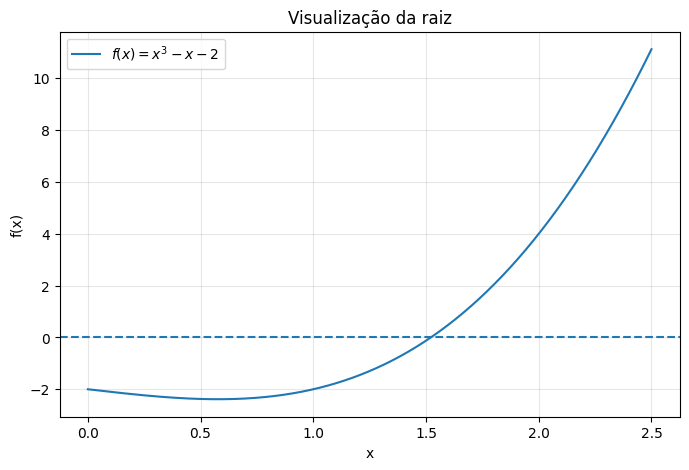

In [2]:
def f(x):
    return x**3 - x - 2

x = np.linspace(0, 2.5, 500)

plt.figure(figsize=(8,5))
plt.plot(x, f(x), label=r"$f(x)=x^3-x-2$")
plt.axhline(0, linestyle="--")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Visualização da raiz")
plt.legend()
plt.show()

## 3. Método da bisseção

O método da bisseção parte de um intervalo \([a,b]\) tal que:

$$
f(a)f(b)<0
$$

Pelo Teorema do Valor Intermediário, existe pelo menos uma raiz em \([a,b]\).

A cada iteração:

$$
c=\frac{a+b}{2}
$$

e o intervalo é reduzido pela metade.

In [3]:
from pyNuMeth import bissecao

### 3.1. Aplicação da bisseção ao exemplo principal

In [4]:
raiz, hist_bis = bissecao(f, 1, 2, tol=1e-8)

print("Raiz aproximada:", raiz)
print("f(raiz):", f(raiz))
print("Número de iterações:", len(hist_bis))

print("\nPrimeiras iterações:")
for item in hist_bis[:8]:
    print(item)

Raiz aproximada: 1.5213797017931938
f(raiz): -2.978654611851539e-08
Número de iterações: 27

Primeiras iterações:
{'iter': 1, 'a': 1, 'b': 2, 'c': 1.5, 'f(c)': -0.125, 'erro_intervalo': 0.5}
{'iter': 2, 'a': 1.5, 'b': 2, 'c': 1.75, 'f(c)': 1.609375, 'erro_intervalo': 0.25}
{'iter': 3, 'a': 1.5, 'b': 1.75, 'c': 1.625, 'f(c)': 0.666015625, 'erro_intervalo': 0.125}
{'iter': 4, 'a': 1.5, 'b': 1.625, 'c': 1.5625, 'f(c)': 0.252197265625, 'erro_intervalo': 0.0625}
{'iter': 5, 'a': 1.5, 'b': 1.5625, 'c': 1.53125, 'f(c)': 0.059112548828125, 'erro_intervalo': 0.03125}
{'iter': 6, 'a': 1.5, 'b': 1.53125, 'c': 1.515625, 'f(c)': -0.034053802490234375, 'erro_intervalo': 0.015625}
{'iter': 7, 'a': 1.515625, 'b': 1.53125, 'c': 1.5234375, 'f(c)': 0.012250423431396484, 'erro_intervalo': 0.0078125}
{'iter': 8, 'a': 1.515625, 'b': 1.5234375, 'c': 1.51953125, 'f(c)': -0.010971248149871826, 'erro_intervalo': 0.00390625}


In [5]:
# Construir um dataframe para visualização
df_bis = pd.DataFrame(hist_bis)
print("\nDataFrame das iterações:")
# Visualizar com display mas sem mostrar o índice do DataFrame
colunas_float = ['a', 'b', 'c', 'f(c)', 'erro_intervalo']
display(df_bis.style.hide(axis="index").format('{:.9f}', subset=colunas_float))


DataFrame das iterações:


iter,a,b,c,f(c),erro_intervalo
1,1.000000000,2.000000000,1.500000000,-0.125000000,0.500000000
2,1.500000000,2.000000000,1.750000000,1.609375000,0.250000000
3,1.500000000,1.750000000,1.625000000,0.666015625,0.125000000
4,1.500000000,1.625000000,1.562500000,0.252197266,0.062500000
5,1.500000000,1.562500000,1.531250000,0.059112549,0.031250000
6,1.500000000,1.531250000,1.515625000,-0.034053802,0.015625000
7,1.515625000,1.531250000,1.523437500,0.012250423,0.007812500
8,1.515625000,1.523437500,1.519531250,-0.010971248,0.003906250
9,1.519531250,1.523437500,1.521484375,0.000622176,0.001953125
10,1.519531250,1.521484375,1.520507812,-0.005178886,0.000976562


### 3.2. Convergência do método da bisseção

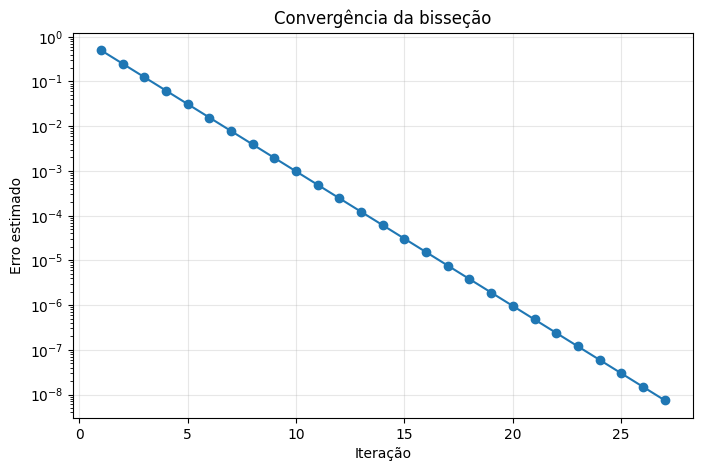

In [6]:
iters = [item["iter"] for item in hist_bis]
erros = [item["erro_intervalo"] for item in hist_bis]

plt.figure(figsize=(8,5))
plt.plot(iters, erros, marker="o")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel("Erro estimado")
plt.title("Convergência da bisseção")
plt.show()

## 4. Estimativa teórica do número de iterações

Na bisseção, após \(n\) iterações:

$$
|e_n| \leq \frac{b-a}{2^n}
$$

Logo, para garantir erro menor que $\varepsilon$:

$$
n \geq \frac{\log((b-a)/\varepsilon)}{\log 2}
$$

In [7]:
a, b = 1, 2
tol = 1e-8

n_teorico = np.ceil(np.log((b-a)/tol) / np.log(2))
print("Número mínimo teórico de iterações:", int(n_teorico))
print("Número observado:", len(hist_bis))

Número mínimo teórico de iterações: 27
Número observado: 27


## 5. Método do ponto fixo

A ideia é transformar:

$$
f(x)=0
$$

em:

$$
x=g(x)
$$

e então construir a sequência:

$$
x_{n+1}=g(x_n)
$$

In [8]:
from pyNuMeth import ponto_fixo

Para o problema:

$$
x^3-x-2=0
$$

uma forma possível é:

$$
g_1(x)=(x+2)^{1/3}
$$

In [9]:
def g1(x):
    return (x + 2)**(1/3)

raiz_pf, hist_pf = ponto_fixo(g1, x0=1.0, tol=1e-8, max_iter=100)

print("Raiz aproximada:", raiz_pf)
print("f(raiz):", f(raiz_pf))
print("Número de iterações:", len(hist_pf))

print("\nPrimeiras iterações:")
for item in hist_pf[:10]:
    print(item)

Raiz aproximada: 1.5213797064982224
f(raiz): -1.820850803468943e-09
Número de iterações: 12

Primeiras iterações:
{'iter': 0, 'x_anterior': None, 'x_novo': 1.0, 'erro': None}
{'iter': 1, 'x_anterior': 1.0, 'x_novo': 1.4422495703074083, 'erro': 0.4422495703074083}
{'iter': 2, 'x_anterior': 1.4422495703074083, 'x_novo': 1.5098974493323554, 'erro': 0.06764787902494707}
{'iter': 3, 'x_anterior': 1.5098974493323554, 'x_novo': 1.5197243049916358, 'erro': 0.009826855659280431}
{'iter': 4, 'x_anterior': 1.5197243049916358, 'x_novo': 1.5211412690627313, 'erro': 0.0014169640710954834}
{'iter': 5, 'x_anterior': 1.5211412690627313, 'x_novo': 1.5213453677519027, 'erro': 0.00020409868917137253}
{'iter': 6, 'x_anterior': 1.5213453677519027, 'x_novo': 1.521374761497894, 'erro': 2.939374599142397e-05}
{'iter': 7, 'x_anterior': 1.521374761497894, 'x_novo': 1.5213789946128164, 'erro': 4.233114922369552e-06}
{'iter': 8, 'x_anterior': 1.5213789946128164, 'x_novo': 1.5213796042392627, 'erro': 6.096264462129

In [10]:
# Construir um dataframe para visualização
df_pf = pd.DataFrame(hist_pf)
print("\nDataFrame das iterações:")
# Visualizar com display mas sem mostrar o índice do DataFrame
colunas_float = ['x_anterior', 'x_novo', 'erro']
display(df_pf.style.hide(axis="index").format('{:.9f}', subset=colunas_float))
#display(df_pf.style.hide(axis="index"))


DataFrame das iterações:


iter,x_anterior,x_novo,erro
0,nan,1.000000000,nan
1,1.000000000,1.442249570,0.442249570
2,1.442249570,1.509897449,0.067647879
3,1.509897449,1.519724305,0.009826856
4,1.519724305,1.521141269,0.001416964
5,1.521141269,1.521345368,0.000204099
6,1.521345368,1.521374761,0.000029394
7,1.521374761,1.521378995,0.000004233
8,1.521378995,1.521379604,0.000000610
9,1.521379604,1.521379692,0.000000088


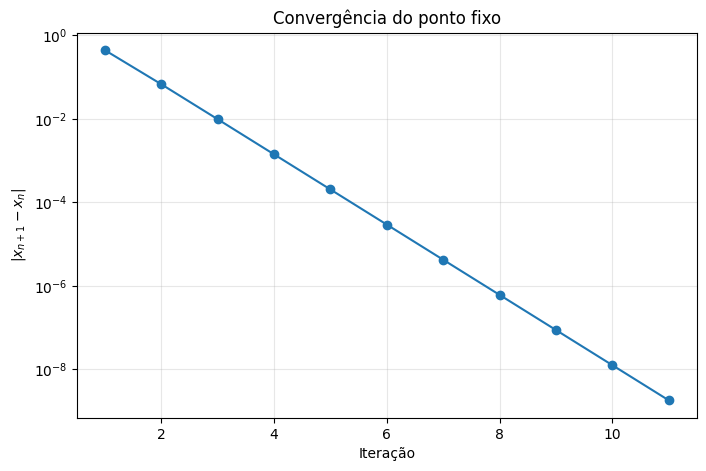

In [11]:
iters = [item["iter"] for item in hist_pf]
erros = [item["erro"] for item in hist_pf]

plt.figure(figsize=(8,5))
plt.plot(iters, erros, marker="o")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel(r"$|x_{n+1}-x_n|$")
plt.title("Convergência do ponto fixo")
plt.show()

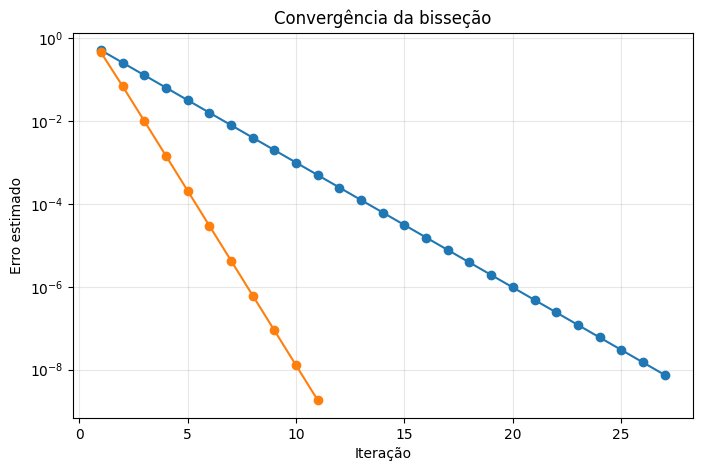

In [12]:

iters_bs = [item["iter"] for item in hist_bis]
erros_bs = [item["erro_intervalo"] for item in hist_bis]

iters_pf = [item["iter"] for item in hist_pf]
erros_pf = [item["erro"] for item in hist_pf]


plt.figure(figsize=(8,5))
plt.plot(iters_bs, erros_bs, marker="o")
plt.plot(iters_pf, erros_pf, marker="o", label="Ponto Fixo")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel("Erro estimado")
plt.title("Convergência da bisseção")
plt.show()


## 6. Visualização geométrica do ponto fixo

Um ponto fixo satisfaz:

$$
x=g(x)
$$

Geometricamente, é uma interseção entre \(y=g(x)\) e \(y=x\).

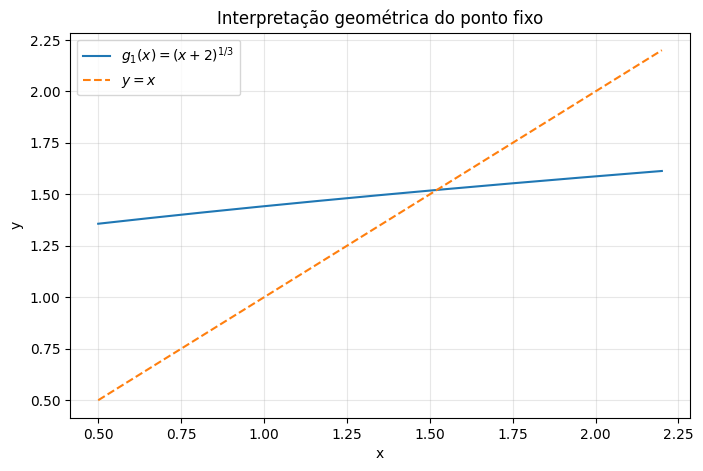

In [13]:
x = np.linspace(0.5, 2.2, 500)

plt.figure(figsize=(8,5))
plt.plot(x, g1(x), label=r"$g_1(x)=(x+2)^{1/3}$")
plt.plot(x, x, "--", label=r"$y=x$")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpretação geométrica do ponto fixo")
plt.legend()
plt.show()

## 7. Escolhas diferentes de \(g(x)\)

A escolha da função \(g(x)\) é crucial.

Uma forma inadequada para o mesmo problema é:

$$
g_2(x)=x^3-2
$$

In [14]:
def g2(x):
    return x**3 - 2

raiz_pf2, hist_pf2 = ponto_fixo(g2, x0=1.5, tol=1e-8, max_iter=10)
for item in hist_pf2:
    print(item)


{'iter': 0, 'x_anterior': None, 'x_novo': 1.5, 'erro': None}
{'iter': 1, 'x_anterior': 1.5, 'x_novo': 1.375, 'erro': 0.125}
{'iter': 2, 'x_anterior': 1.375, 'x_novo': 0.599609375, 'erro': 0.775390625}
{'iter': 3, 'x_anterior': 0.599609375, 'x_novo': -1.7844216004014015, 'erro': 2.3840309754014015}
{'iter': 4, 'x_anterior': -1.7844216004014015, 'x_novo': -7.681884682517707, 'erro': 5.897463082116306}
{'iter': 5, 'x_anterior': -7.681884682517707, 'x_novo': -455.31840313982127, 'erro': 447.63651845730357}
{'iter': 6, 'x_anterior': -455.31840313982127, 'x_novo': -94394267.64680803, 'erro': 94393812.32840489}
{'iter': 7, 'x_anterior': -94394267.64680803, 'x_novo': -8.410791441169053e+23, 'erro': 8.410791441169052e+23}
{'iter': 8, 'x_anterior': -8.410791441169053e+23, 'x_novo': -5.949912681944878e+71, 'erro': 5.949912681944878e+71}
{'iter': 9, 'x_anterior': -5.949912681944878e+71, 'x_novo': -2.106356013037562e+215, 'erro': 2.106356013037562e+215}


In [15]:
# Construir um dataframe para visualização
df_pf2 = pd.DataFrame(hist_pf2)
print("\nDataFrame das iterações:")
# Visualizar com display mas sem mosytrar o índice do DataFrame
display(df_pf2.style.hide(axis="index"))


DataFrame das iterações:


iter,x_anterior,x_novo,erro
0,nan,1.500000,nan
1,1.500000,1.375000,0.125000
2,1.375000,0.599609,0.775391
3,0.599609,-1.784422,2.384031
4,-1.784422,-7.681885,5.897463
5,-7.681885,-455.318403,447.636518
6,-455.318403,-94394267.646808,94393812.328405
7,-94394267.646808,-841079144116905333227520.000000,841079144116905199009792.000000
8,-841079144116905333227520.000000,-594991268194487757000066039029022766489900464602685937020567771714420736.000000,594991268194487757000066039029022766489900464602685937020567771714420736.000000
9,-594991268194487757000066039029022766489900464602685937020567771714420736.000000,-210635601303756217833247375401715259769474974730796218351403496378040115294835935021382321620912463391330907916242240514728827106941521769039827849979729292272357548370102544239943910514682031628764521230192699506688.000000,210635601303756217833247375401715259769474974730796218351403496378040115294835935021382321620912463391330907916242240514728827106941521769039827849979729292272357548370102544239943910514682031628764521230192699506688.000000


### 7.1. Comparação visual das iterações

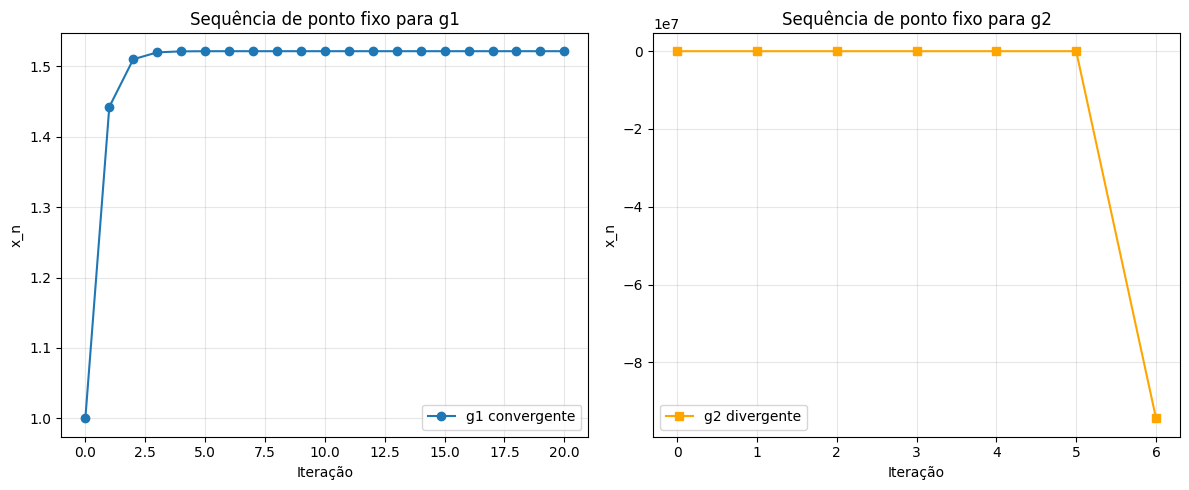

In [16]:
def sequencia_ponto_fixo(g, x0, n):
    seq = [x0]
    for _ in range(n):
        seq.append(g(seq[-1]))
    return np.array(seq)

seq_g1 = sequencia_ponto_fixo(g1, 1.0, 20)
seq_g2 = sequencia_ponto_fixo(g2, 1.5, 6)

# vamos gerar dois subplots lado a lado para comparar as duas sequencias em escalas diferentes
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
plt.plot(seq_g1, marker="o", label="g1 convergente")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel("x_n")
plt.title("Sequência de ponto fixo para g1")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(seq_g2, marker="s", label="g2 divergente", color="orange")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel("x_n")
plt.title("Sequência de ponto fixo para g2")
plt.legend()
plt.tight_layout()
plt.show()    

__Exemplo__: A equação $xˆ3 + 4xˆ2 - 10 = 0$ tem uma única raiz em $[1, 2]$. Existem muitas maneiras de transformar a equação para a forma de ponto fixo $x = g(x)$ usando manipulação algébrica simples. Não é importante que você derive as funções mostradas aqui, mas você deve verificar se o ponto fixo de cada uma é de fato uma solução da equação original, $xˆ3 + 4xˆ2 - 10 = 0$.

a) $x = g_1(x) = x - x^3 -4x^2 + 10$

b) $x = g_2(x) = ( \frac{10}{x} - 4x )^{1/2}$

c) $x = g_3(x) = \frac{1}{2}(10 - x^3)^{1/2}$

d) $x = g_4(x) = (\frac{10}{4+x})^{1/2}$

e) $x = g_5(x) = x - \frac{x^3+4x^2-10}{3x^2+8x}$

In [17]:
def f_exemplo(x):
    return x**3 + 4*x**2 - 10

raiz_bis_exemplo, hist_bis_exemplo = bissecao(f_exemplo, 1, 2, tol=1e-8)
print("Raiz aproximada:", raiz_bis_exemplo)
print("f(raiz):", f_exemplo(raiz_bis_exemplo))
print("Número de iterações:", len(hist_bis_exemplo))

Raiz aproximada: 1.3652300164103508
f(raiz): 4.94783378712782e-08
Número de iterações: 27


In [18]:
def g1_exemplo(x):
    """$x = g_1(x) = x - x^3 -4x^2 + 10$"""
    return x - x**3.0 - 4*x**2.0 + 10

def g2_exemplo(x):
    """$x = g_2(x) = ( \frac{10}{x} - 4x )^{1/2}$"""
    return np.sqrt((10/x) - 4*x)

def g3_exemplo(x):
    """$x = g_3(x) = \frac{1}{2}(10 - x^3)^{1/2}$"""
    return np.sqrt((10 - x**3))/2

def g4_exemplo(x):
    """$x = g_4(x) = ( \frac{10}{4+x} )^{1/2}$"""
    return np.sqrt(10/(4+x))

def g5_exemplo(x):
    """$$x = g_5(x) = x - \frac{x^3+4x^2-10}{3x^2+8x}$$"""
    return x - (x**3 + 4*x**2 - 10)/(3*x**2 + 8*x)


In [19]:
raiz_pf_g1, hist_pf_g1 = ponto_fixo(g1_exemplo, x0=1.5, tol=1e-8, max_iter=100)
print("Raiz aproximada (g1):", raiz_pf_g1)
#print("f(raiz):", f_exemplo(raiz_pf_g1))
print("Número de iterações (g1):", len(hist_pf_g1))

Raiz aproximada (g1): -2.082712908581025e+216
Número de iterações (g1): 8


In [20]:
# construindo um dataframe com cabeçalho n, (a), (b), (c), (d), (e)
# A primeira coluna mostra o número de iterações começando com 0
# as outras colunas mostra o campo x_novo para cada função g1, g2, g3, g4, g5
# Dataframe será construído aos poucos, na medida que os exemplos sejam 
# executados. Começamos então pelo exemplo (a) do qual vamos pegar apenas 
# as 5 primeiras linhas do histórico para não poluir a visualização. 
# Depois vamos acrescentando as outras colunas à medida que os exemplos 
# forem executados. 
df_pf_exemplo = pd.DataFrame({
    "n": [item["iter"] for item in hist_pf_g1[0:5]],
    "(a)": [item["x_novo"] for item in hist_pf_g1[0:5]]
    # "(b)": [item["x_novo"] for item in hist_pf_g2],
    # "(c)": [item["x_novo"] for item in hist_pf_g3],
    # "(d)": [item["x_novo"] for item in hist_pf_g4],
    # "(e)": [item["x_novo"] for item in hist_pf_g5],
})
print("\nDataFrame das iterações para g1:")
colunas_float = ['(a)']
display(df_pf_exemplo.style.hide(axis="index").format('{:.9f}', subset=colunas_float))
#display(df_pf_exemplo.style.hide(axis="index"))


DataFrame das iterações para g1:


n,(a)
0,1.500000000
1,-0.875000000
2,6.732421875
3,-469.720012002
4,102754555.187385112


In [21]:
raiz_pf_g2, hist_pf_g2 = ponto_fixo(g2_exemplo, x0=1.5, tol=1e-8, max_iter=100)
print("Raiz aproximada (g2):", raiz_pf_g2)
#print("f(raiz):", f_exemplo(raiz_pf_g2))
print("Número de iterações (g2):", len(hist_pf_g2))

Raiz aproximada (g2): nan
Número de iterações (g2): 101


/var/folders/k8/m4nwfbmx7517ksbqt7fkxclm0000gn/T/ipykernel_52763/471947717.py:7: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt((10/x) - 4*x)


In [22]:
# Agora vamos acrescentar a coluna (b) ao dataframe
df_pf_exemplo["(b)"] = [item["x_novo"] for item in hist_pf_g2[0:5]]
print("\nDataFrame das iterações para g1 e g2:")
colunas_float = ['(a)', '(b)']
display(df_pf_exemplo.style.hide(axis="index").format('{:.9f}', subset=colunas_float))


DataFrame das iterações para g1 e g2:


n,(a),(b)
0,1.500000000,1.500000000
1,-0.875000000,0.816496581
2,6.732421875,2.996908806
3,-469.720012002,nan
4,102754555.187385112,nan


In [23]:
raiz_pf_g3, hist_pf_g3 = ponto_fixo(g3_exemplo, x0=1.5, tol=1e-8, max_iter=100)
print("Raiz aproximada (g3):", raiz_pf_g3)
print("f(raiz):", f_exemplo(raiz_pf_g3))
print("Número de iterações (g3):", len(hist_pf_g3))

Raiz aproximada (g3): 1.365230011360733
f(raiz): -3.390801772695795e-08
Número de iterações (g3): 28


In [24]:
# Agora vamos acrescentar a coluna (c) ao dataframe. Para poder fazer tem que 
# aumentar o número de linhas do DataFrame porque o novo exemplo tem muito mais 
# linhas. A coluna "n" já existe então não precisa ser recriada, mas novos valores
# devem ser adicionados no final da  mesma. Depois basta criar a 
# coluna (c) e preencher com os dados do exemplo g3.
# Formatar a saída para mostrar apenas 8 casas decimais
df_pf_exemplo = pd.DataFrame({
    "n": [item["iter"] for item in hist_pf_g1[0:5]] + [item["iter"] for item in hist_pf_g3[5:28]],
    "(a)": [item["x_novo"] for item in hist_pf_g1[0:5]] + [None]*(28-5),
    "(b)": [item["x_novo"] for item in hist_pf_g2[0:5]] + [None]*(28-5),
    "(c)": [item["x_novo"] for item in hist_pf_g3],
    # "(d)": [item["x_novo"] for item in hist_pf_g4],
    # "(e)": [item["x_novo"] for item in hist_pf_g5],
})
print("\nDataFrame das iterações para g1, g2 e g3:")
colunas_float = ['(a)', '(b)', '(c)']
display(df_pf_exemplo.style.hide(axis="index").format('{:.9f}', subset=colunas_float))



DataFrame das iterações para g1, g2 e g3:


n,(a),(b),(c)
0,1.500000000,1.500000000,1.500000000
1,-0.875000000,0.816496581,1.286953768
2,6.732421875,2.996908806,1.402540804
3,-469.720012002,nan,1.345458374
4,102754555.187385112,nan,1.375170253
5,nan,nan,1.360094193
6,nan,nan,1.367846968
7,nan,nan,1.363887004
8,nan,nan,1.365916733
9,nan,nan,1.364878217


In [25]:
raiz_pf_g4, hist_pf_g4 = ponto_fixo(g4_exemplo, x0=1.5, tol=1e-8, max_iter=100)
print("Raiz aproximada (g4):", raiz_pf_g4)
print("f(raiz):", f_exemplo(raiz_pf_g4))
print("Número de iterações (g4):", len(hist_pf_g4))

Raiz aproximada (g4): 1.3652300135614253
f(raiz): 2.432892998172065e-09
Número de iterações (g4): 11


In [27]:
# Agora vamos acrescentar a coluna (d) ao dataframe
df_pf_exemplo["(d)"] = [item["x_novo"] for item in hist_pf_g4[0:12]] + [None]*(28-11)
print("\nDataFrame das iterações para g1, g2 e g4:")
colunas_float = ['(a)', '(b)', '(c)', '(d)']
display(df_pf_exemplo.style.hide(axis="index").format('{:.9f}', subset=colunas_float))


DataFrame das iterações para g1, g2 e g4:


n,(a),(b),(c),(d)
0,1.500000000,1.500000000,1.500000000,1.500000000
1,-0.875000000,0.816496581,1.286953768,1.348399725
2,6.732421875,2.996908806,1.402540804,1.367376372
3,-469.720012002,nan,1.345458374,1.364957015
4,102754555.187385112,nan,1.375170253,1.365264748
5,nan,nan,1.360094193,1.365225594
6,nan,nan,1.367846968,1.365230576
7,nan,nan,1.363887004,1.365229942
8,nan,nan,1.365916733,1.365230023
9,nan,nan,1.364878217,1.365230012


In [28]:
def g5_exemplo(x):
    return(x - (x**3+4*x**2-10)/(3*x**2 + 8*x))

In [29]:
raiz_pf_g5, hist_pf_g5 = ponto_fixo(g5_exemplo, x0=1.5, tol=1e-8, max_iter=100)
print("Raiz aproximada (g5):", raiz_pf_g5)
print("f(raiz):", f_exemplo(raiz_pf_g5))
print("Número de iterações (g5):", len(hist_pf_g5))

Raiz aproximada (g5): 1.3652300134140969
f(raiz): 0.0
Número de iterações (g5): 5


## 8. Condição de convergência para ponto fixo

Uma condição suficiente para convergência local é:
$$
|g'(x)| < 1
$$

em uma vizinhança da raiz.

In [ ]:
def dg1(x):
    return (1/3)*(x+2)**(-2/3)

def dg2(x):
    return 3*x**2

x_star = raiz_pf

print("Raiz aproximada:", x_star)
print("|g1'(x*)| =", abs(dg1(x_star)))
print("|g2'(x*)| =", abs(dg2(x_star)))

## 9. Comparação entre bisseção e ponto fixo

In [ ]:
print("Bisseção:")
print("Raiz:", raiz)
print("Iterações:", len(hist_bis))
print("f(raiz):", f(raiz))

print("\nPonto fixo:")
print("Raiz:", raiz_pf)
print("Iterações:", len(hist_pf))
print("f(raiz):", f(raiz_pf))

In [ ]:
erros_bis = np.array([item["erro_intervalo"] for item in hist_bis])
erros_pf = np.array([item["erro"] for item in hist_pf])

plt.figure(figsize=(8,5))
plt.plot(range(1, len(erros_bis)+1), erros_bis, marker="o", label="Bisseção")
plt.plot(range(1, len(erros_pf)+1), erros_pf, marker="s", label="Ponto fixo")
plt.yscale("log")
plt.grid(True, alpha=0.3)
plt.xlabel("Iteração")
plt.ylabel("Erro estimado")
plt.title("Comparação de convergência")
plt.legend()
plt.show()

## 10. Exemplo aplicado: corrente em circuito com diodo

Em um circuito com fonte \(V\), resistor \(R\) e diodo, obtemos:

\[
I = I_s\left(e^{\frac{V-RI}{nV_T}}-1\right)
\]

Rearranjando:

\[
f(I)=I-I_s\left(e^{\frac{V-RI}{nV_T}}-1\right)=0
\]

In [ ]:
Is = 1e-12
V = 5.0
R = 1000.0
VT = 0.025
n = 1.0

def f_diodo(I):
    return I - Is*(np.exp((V - R*I)/(n*VT)) - 1)

I_vals = np.linspace(0.0001, 0.005, 1000)

plt.figure(figsize=(8,5))
plt.plot(I_vals, f_diodo(I_vals))
plt.axhline(0, linestyle="--")
plt.grid(True, alpha=0.3)
plt.xlabel("Corrente I (A)")
plt.ylabel("f(I)")
plt.title("Raiz associada ao ponto de operação do diodo")
plt.show()

In [ ]:
raiz_diodo, hist_diodo = bissecao(f_diodo, 0.0001, 0.005, tol=1e-10, max_iter=200)

print("Corrente aproximada:", raiz_diodo, "A")
print("f(I):", f_diodo(raiz_diodo))
print("Iterações:", len(hist_diodo))

## 11. Síntese da aula

Nesta aula vimos que:

1. encontrar raízes é um problema central em modelagem;
2. o método da bisseção é robusto, mas geralmente lento;
3. o método do ponto fixo depende fortemente da escolha de \(g(x)\);
4. a condição \(|g'(x)|<1\) ajuda a compreender convergência;
5. exemplos de engenharia frequentemente levam naturalmente a equações não lineares.

## 12. Sugestões para exploração em sala

- Alterar o intervalo inicial da bisseção;
- Testar diferentes tolerâncias;
- Criar outras funções \(g(x)\) para o mesmo problema;
- Comparar convergência e divergência;
- Adaptar o exemplo do diodo para outros valores de \(R\), \(V\) ou \(I_s\).